# 06 · Tuning, Ensembles, Calibration, Risk Score and Explanations — FinSight AI
**Phase 7 · Subject: ML** (the risk score and serving artifacts feed CCT Phase 8) · KDD steps 6–7

| RQ | Question |
|---|---|
| **RQ4** | Which classifier performs best, **with which hyperparameters**? Does an ensemble beat the best single model? |
| — | Can the model's output be turned into a calibrated, explainable 0–100 risk score with operational tiers? |

### Protocol (Plan §7.6–7.9; v1.1, Exp C, same 60/20/20 split as Phases 5–6)
| Split | Used for |
|---|---|
| **train** (6,000) | hyperparameter search (5-fold stratified CV, PR-AUC), learning curves, stacking + isotonic calibration fit, network-flag fraud rates |
| **validation** (2,000) | choice of production model, decision threshold, risk-score weights and tier cut-offs, permutation importance |
| **test** (2,000) | scored **once** at the end; nothing is chosen on it |

Imbalance follows D-020 (class weights for trees, no SMOTE). All computation is in `finsight.ml.final_model` (pipeline stage `train_final`). This notebook reloads the saved artifacts and reports.

In [1]:
import warnings, json; warnings.filterwarnings("ignore")
import joblib, numpy as np, pandas as pd
from IPython.display import display, Image
from finsight import viz, config
from finsight.eda import load_master
from finsight.ml import final_figures as F, explain as X_
from finsight.ml.final_model import anomaly_component
from finsight.ml.evaluator import scores
from finsight.ml.feature_sets import get_xy
from finsight.ml.splits import stratified_split
from finsight.scoring import risk_scorer as RS
viz.apply_style()
pd.set_option("display.width", 220, "display.max_columns", 30, "display.max_colwidth", 120)
R, FIN = config.REPORTS_DIR, config.ARTIFACTS_DIR / "models" / "final"
S = json.loads((R / "final_summary.json").read_text())
tsum = pd.read_csv(R / "final_tuning_summary.csv"); tres = pd.read_csv(R / "final_tuning_results.csv")
lc = pd.read_csv(R / "final_learning_curves.csv"); comp = pd.read_csv(R / "final_model_comparison.csv")
tiers = pd.read_csv(R / "final_risk_tiers.csv")
m = load_master("v1_1"); sp = stratified_split(m); X, y = get_xy(m, "C")
Xte, yte, te = X.iloc[sp.test], y.to_numpy()[sp.test], m.iloc[sp.test]
print("production model:", S["production_model"], "| split:", S["split_sizes"])

production model: xgboost_calibrated | split: {'train': 6000, 'val': 2000, 'test': 2000}


## 1 · Hyperparameter tuning (RQ4: which hyperparameters?)

,model,search,configs_tried,default_cv_pr_auc,tuned_cv_pr_auc,paired_mean_diff,paired_t_pvalue,seconds,best_params
0,decision_tree,grid,70,0.7921,0.8504,0.0583,0.0054,17.1,"{""criterion"": ""entropy"", ""max_depth"": 8, ""min_samples_leaf"": 40}"
1,knn,grid,24,0.7888,0.8173,0.0284,0.0088,39.7,"{""n_neighbors"": 15, ""p"": 1, ""weights"": ""distance""}"
2,random_forest,random,20,0.8809,0.9059,0.0250,0.0043,181.5,"{""n_estimators"": 300, ""min_samples_leaf"": 2, ""max_features"": 0.2, ""max_depth"": null, ""class_weight"": null}"
3,xgboost,random,20,0.8949,0.9087,0.0139,0.0002,32.2,"{""colsample_bytree"": 0.8081845231526679, ""gamma"": 0, ""learning_rate"": 0.02385264834812575, ""max_depth"": 6, ""min_chil..."
4,mlp,random,10,0.8510,0.8618,0.0108,0.1334,22.8,"{""alpha"": 0.004013783023846251, ""batch_size"": 64, ""hidden_layer_sizes"": [128], ""learning_rate_init"": 0.0015816851129..."


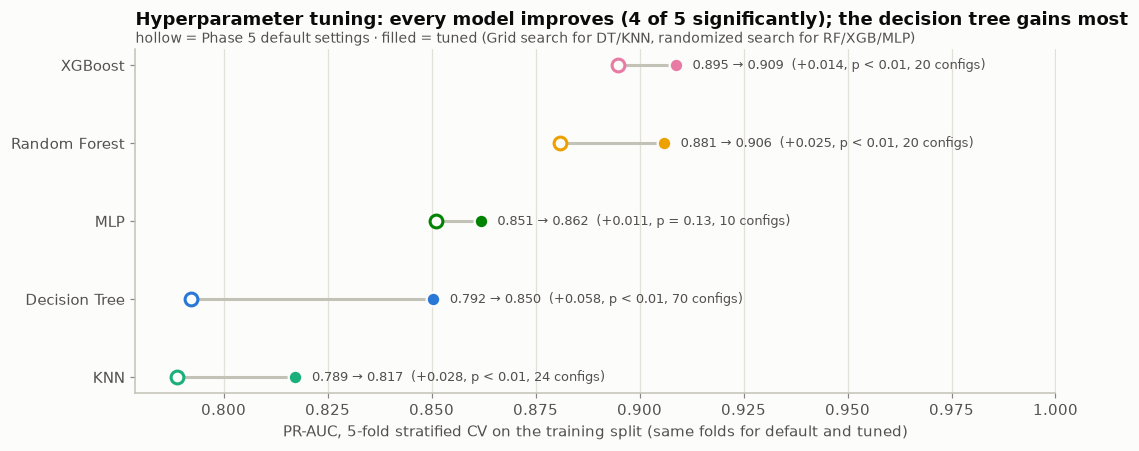

In [2]:
F.fig_tuning(tsum);
display(tsum[["model", "search", "configs_tried", "default_cv_pr_auc", "tuned_cv_pr_auc", "paired_mean_diff", "paired_t_pvalue", "seconds", "best_params"]].round(4))

- **Grid search** for the small discrete spaces (Decision Tree: 70 combinations, KNN: 24); **randomized search** for the large or continuous spaces (Random Forest and XGBoost: 20 draws each, MLP: 10). Randomized search covers a large space at fixed cost: 20 XGBoost draws took ~30 s, while a comparable grid would need thousands of fits.
- Default and tuned settings are scored on **the same 5 folds**, so the gain is a paired comparison. Four of five models improve significantly (p < 0.01). The MLP gains +0.011, which is not significant (p = 0.13).
- The **Decision Tree gains most (+0.058)**: the default depth-8, leaf-5 tree overfits, and the search picks entropy, depth 8 and **40 rows per leaf**, i.e. heavier regularisation.
- Tuned XGBoost uses a low learning rate (≈ 0.024) with ~465 trees and depth 6: many small boosting steps. Tuned Random Forest uses `max_features = 0.2` (more decorrelated trees) and no class weights.

## 2 · Bias–variance: validation curve and learning curves

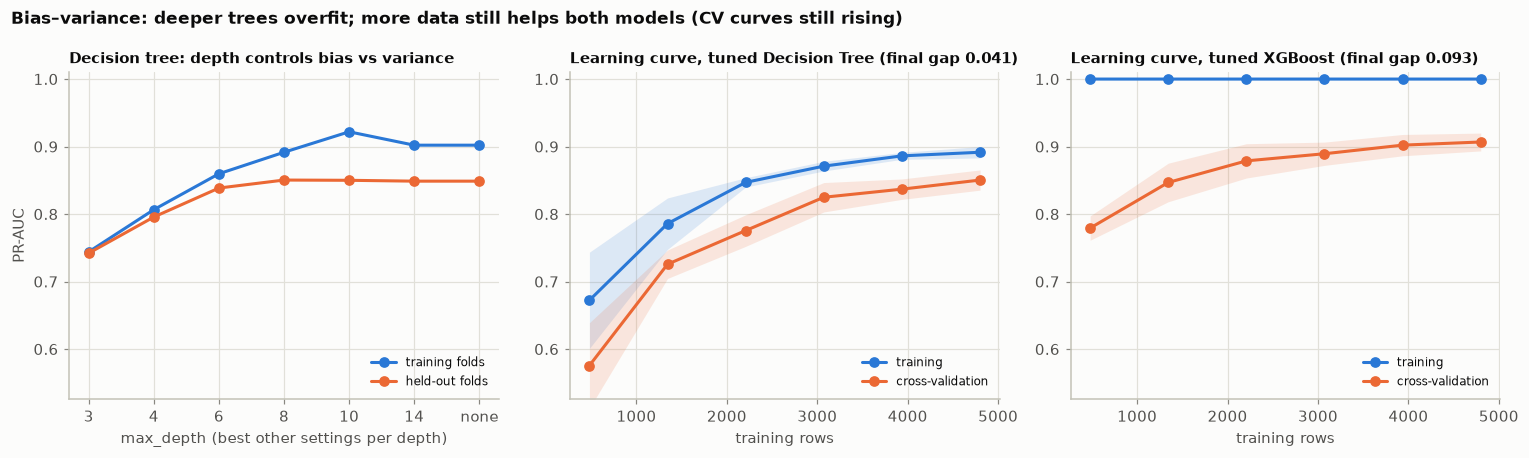

In [3]:
F.fig_bias_variance(tres, lc);

- **Decision-tree depth (left):** at depth 3 both training and held-out scores are low (high bias). From depth 8 the training score keeps rising while the held-out score stays flat at ≈ 0.85: extra depth only memorises (variance). The best region is depth 6–10 with large leaves.
- **Learning curves:** tuned XGBoost fits the training folds perfectly (training PR-AUC 1.0), a high-variance learner. Its cross-validation score still rises from 0.78 at ~500 rows to 0.91 at 4,800 rows, so **more data would still help**. The tuned tree has a smaller gap (0.04) but a lower ceiling (≈ 0.85), the classic bias–variance trade-off.

## 3 · Stacking and calibration

stack meta-learner (logistic regression) coefficients: {'intercept': -4.53, 'random_forest': 5.36, 'xgboost': 2.44, 'mlp': 0.61}


,brier,ece
stack_uncalibrated,0.0390,0.0158
stack_calibrated,0.0368,0.0097
xgboost,0.0382,0.0143
xgboost_calibrated,0.0352,0.0047


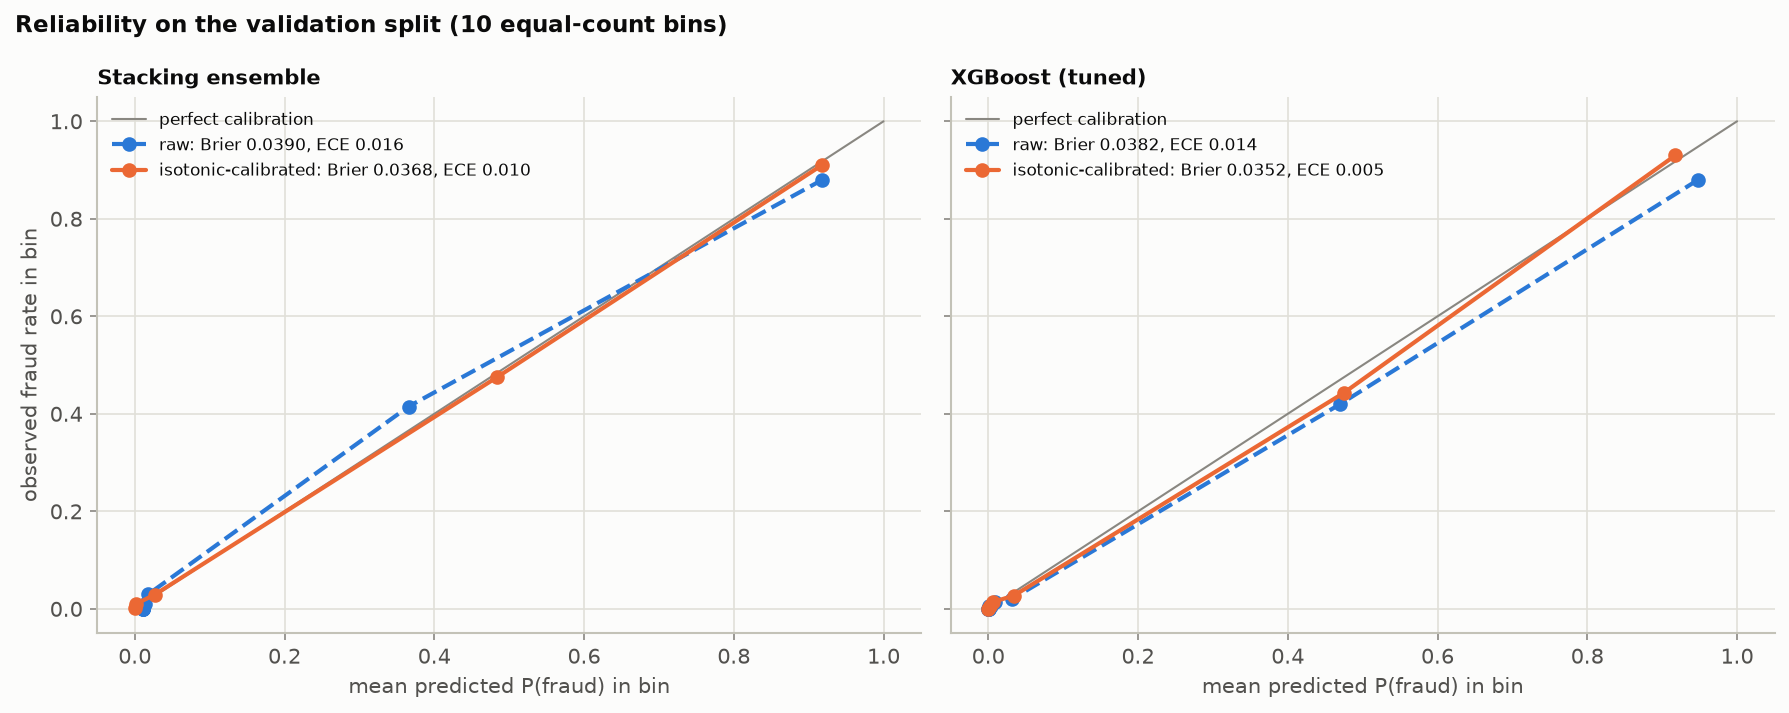

In [4]:
print("stack meta-learner (logistic regression) coefficients:", {k: round(v, 2) for k, v in S["stack_meta_weights"].items()})
display(pd.DataFrame(S["calibration_val"]).T)
display(Image(filename=str(R / "figures" / "final_03_calibration.png")))

- **Stacking** (tuned RF + XGBoost + MLP → logistic regression on 5-fold out-of-fold probabilities) gives validation PR-AUC 0.892 and test 0.889: **no better than tuned XGBoost alone** (0.898 / 0.893). The meta-learner relies mostly on Random Forest (coefficient 5.4) and XGBoost (2.4) and barely on the MLP (0.6). The tree ensembles make highly correlated errors, so combining them adds little. This is a common real-world result and worth reporting.
- **Isotonic calibration** (fitted on out-of-fold predictions; one refitted model is kept, D-029) brings predicted probabilities onto the diagonal. XGBoost's expected calibration error falls from 0.014 to **0.005** and its Brier score from 0.0382 to 0.0352. The price is about −0.01 PR-AUC, because the isotonic step function creates ties in the ranking.
- **Production model (D-031):** the better calibrated candidate on validation, which is **isotonic-calibrated tuned XGBoost** (0.888 vs 0.872 for the calibrated stack). Calibration is required because the probability feeds a 0–100 score. A single XGBoost model also means the native TreeSHAP explanation describes exactly the model in production.

## 4 · Final test results (scored once)

,model,val_pr_auc,test_pr_auc,test_roc_auc,test_f1,test_precision,test_recall,val_threshold
0,decision_tree,0.826,0.846,0.972,0.788,0.703,0.896,0.779
1,knn,0.792,0.788,0.929,0.743,0.704,0.785,0.197
2,random_forest,0.890,0.885,0.981,0.818,0.735,0.922,0.333
3,xgboost,0.898,0.893,0.982,0.826,0.731,0.948,0.215
4,mlp,0.826,0.820,0.967,0.757,0.687,0.844,0.273
5,stack_uncalibrated,0.892,0.889,0.982,0.825,0.751,0.915,0.164
6,xgboost_calibrated,0.888,0.885,0.982,0.827,0.735,0.944,0.271
7,stack_calibrated,0.872,0.869,0.982,0.822,0.753,0.904,0.333


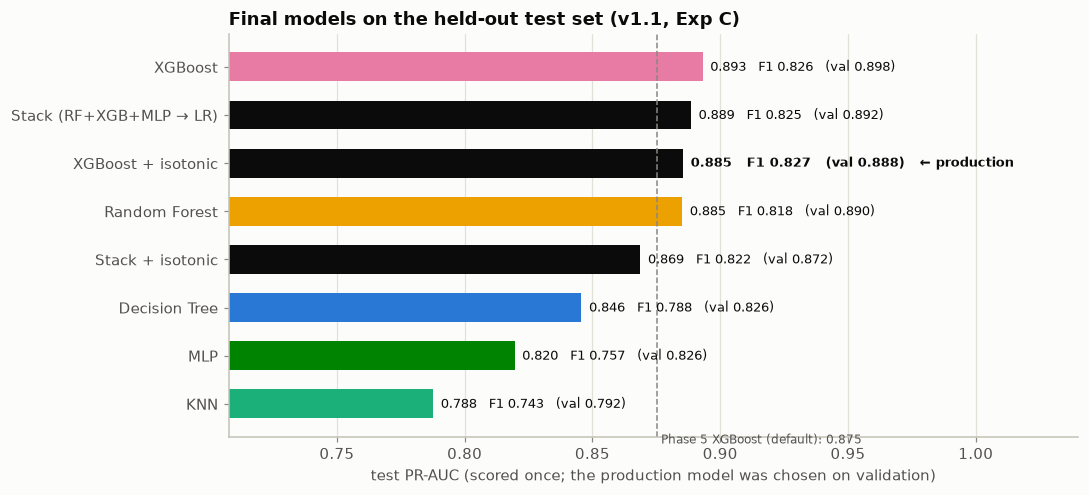

In [5]:
F.fig_test_comparison(comp, S["production_model"], S["phase5_reference_xgboost_default_test_pr_auc"]);
display(comp[["model", "val_pr_auc", "test_pr_auc", "test_roc_auc", "test_f1", "test_precision", "test_recall", "val_threshold"]].round(3))

{'pr_auc': 0.8855, 'roc_auc': 0.9822, 'f1': 0.8266, 'precision': 0.7349, 'recall': 0.9444}
matches metrics.json: True | reload check: {'max_abs_diff_proba': 0.0, 'max_abs_diff_risk': 0.0, 'test_pr_auc_reloaded': 0.8854550908086886, 'pass': True} | artifact sizes (MB): {'production_model.joblib': 0.43, 'xgboost_explainer.joblib': 0.43}


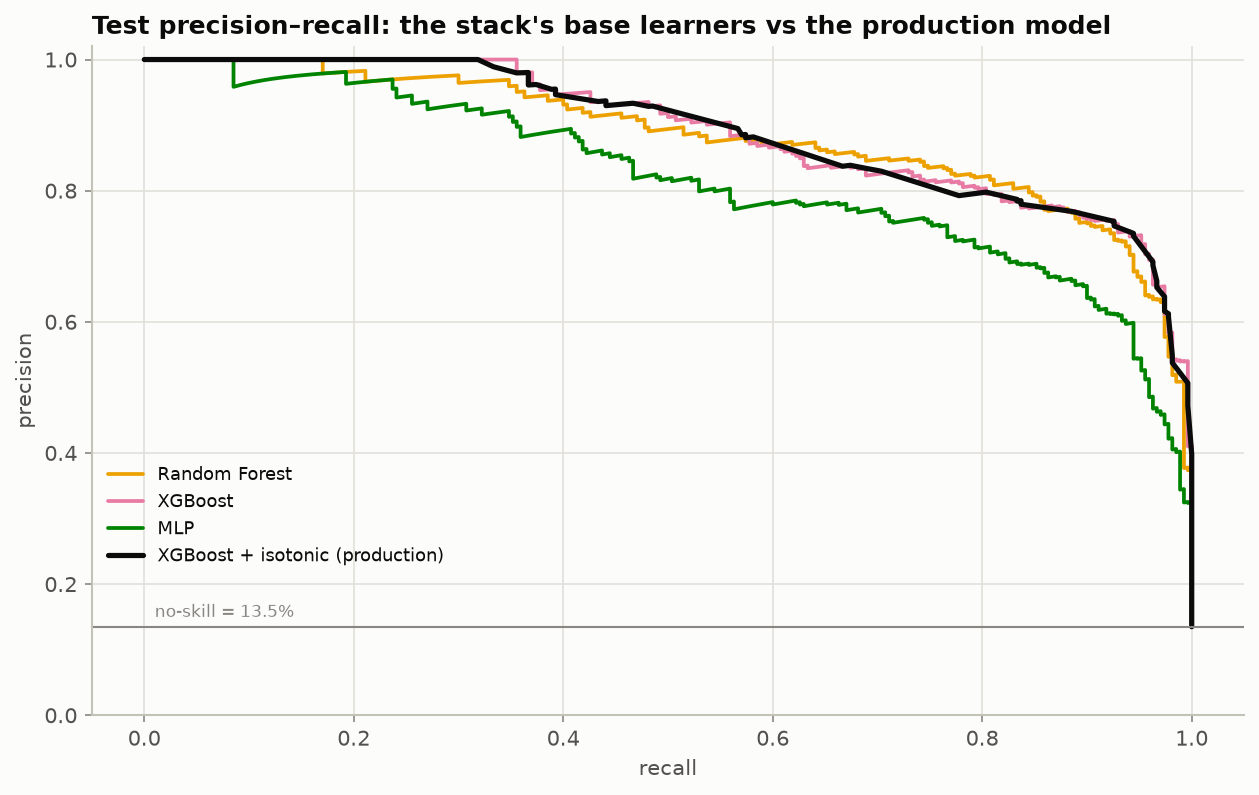

In [6]:
# Acceptance: the saved artifact reproduces the reported test metrics
prod = joblib.load(FIN / "production_model.joblib")
p_test = prod.predict_proba(Xte)[:, 1]
s = scores(yte, p_test, S["decision_threshold"])
print({k: round(v, 4) for k, v in s.items() if k in ("pr_auc", "roc_auc", "f1", "precision", "recall")})
print("matches metrics.json:", np.isclose(s["pr_auc"], S["test"]["test_pr_auc"]) and np.isclose(s["f1"], S["test"]["test_f1"]),
      "| reload check:", S["reload_check"], "| artifact sizes (MB):", S["artifact_sizes_mb"])
display(Image(filename=str(R / "figures" / "final_05_pr_test.png")))

| Model (v1.1, Exp C, test) | PR-AUC | ROC-AUC | F1 | Precision | Recall |
|---|---|---|---|---|---|
| Phase 5 XGBoost (defaults, SMOTE) | 0.875 | 0.980 | 0.801 | 0.70 | 0.94 |
| Tuned XGBoost | 0.893 | 0.982 | 0.826 | 0.73 | 0.95 |
| Stacking (RF + XGB + MLP → LR) | 0.889 | 0.982 | 0.825 | 0.75 | 0.92 |
| **Production: tuned XGBoost + isotonic** | **0.885** | **0.982** | **0.827** | **0.73** | **0.94** |

**Answer to RQ4 (final):** XGBoost is the best classifier, with a low learning rate, ~465 trees, depth 6 and moderate positive-class weighting. Tuning lifts F1 from 0.801 to 0.827 on the same test set. A stacking ensemble does not improve on it. The production artifact is **0.43 MB** (compressed joblib), small enough for a 512 MB free-tier server.

## 5 · The 0–100 risk score

weights: {'model': 0.9, 'anomaly': 0.05, 'graph': 0.05} | cut-offs: {'MEDIUM': 4.8, 'HIGH': 28.4, 'CRITICAL': 74.0}
graph_risk flag rates (train): {'PASS_THROUGH': 1.0, 'QUICK_INFLOW': 0.654, 'HUB_RECEIVER': 0.632, 'BURST_SENDER': 0.458, 'SHARED_DEVICE': 0.205}
risk score test PR-AUC: 0.8924 | overrides: {'structuring': 13, 'pep_floor': 8}


,risk_label,LOW_share,MEDIUM_share,HIGH_share,CRITICAL_share,LOW_n,MEDIUM_n,HIGH_n,CRITICAL_n
0,BORDERLINE,0.022,0.244,0.622,0.111,2,22,56,10
1,FRAUDULENT,0.004,0.059,0.407,0.530,1,16,110,143
2,LEGITIMATE,0.793,0.192,0.015,0.001,1300,315,24,1


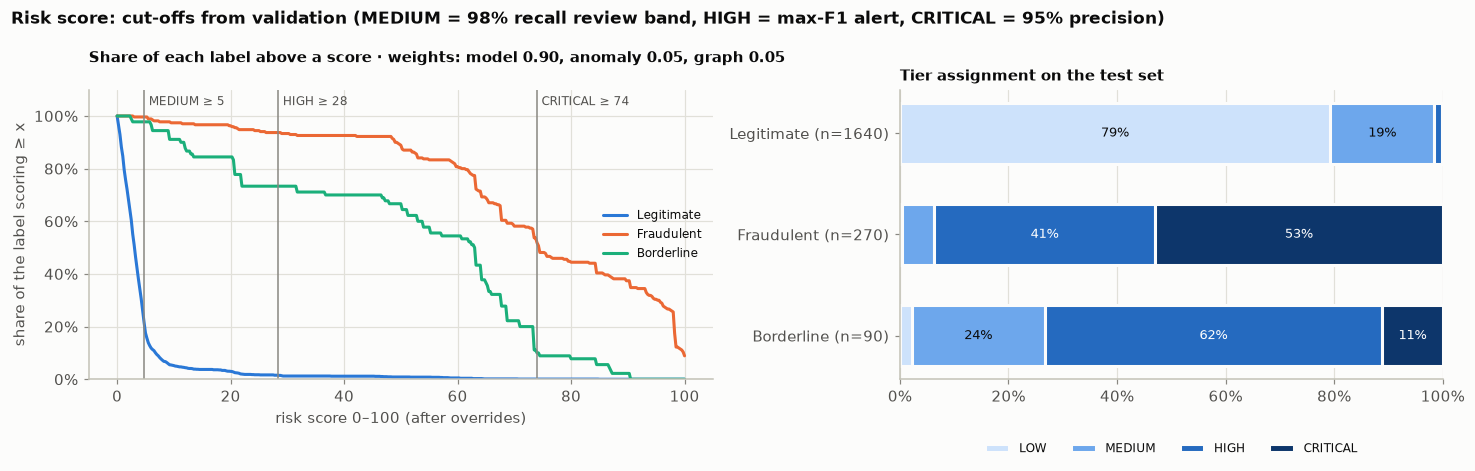

In [7]:
sc = RS.RiskScorer.load(FIN / "risk_scorer.json")
print("weights:", sc.weights, "| cut-offs:", {k: round(v, 1) for k, v in sc.cutoffs.items()})
print("graph_risk flag rates (train):", {k: round(v, 3) for k, v in sc.flag_rates.items()})
flags = RS.network_flags(te)
a = anomaly_component(m)[sp.test]; g = sc.graph_risk(flags)
risk = sc.score(p_test, a, g, pep=te["sender_pep_flag"].to_numpy().astype(bool), structuring=RS.structuring_fired(flags))
print("risk score test PR-AUC:", round(scores(yte, risk["score"])["pr_auc"], 4), "| overrides:", S["risk_overrides_test"])
F.fig_risk(risk, sc, tiers, te);
display(tiers.round(3))

- **Weights** (simplex grid on validation): **model 0.90, anomaly 0.05, graph 0.05**. The anomaly and graph components add a small but real gain: validation PR-AUC 0.888 → 0.896 and test 0.885 → 0.892, consistent with Phase 6, where the autoencoder caught frauds the classifier missed. Most of the network signal is already inside the classifier (Exp C), so `graph_risk` mainly adds *explainability* ("pass-through: 100% of such training rows were fraud").
- **Tiers** (cut-offs from validation, D-032):
  - **CRITICAL ≥ 74:** 95% precision on validation. It holds **53% of all test fraud** and only 1 legitimate transaction.
  - **HIGH ≥ 28:** the max-F1 alert threshold. **94% of fraud is at HIGH or above.**
  - **MEDIUM ≥ 5:** the review band, set so 98% of fraud is at least MEDIUM. It also catches **19% of legitimate rows**. This is a policy knob: a bank with fewer reviewers would raise it.
- **BORDERLINE:** 73% land in HIGH/CRITICAL and 24% in MEDIUM. A dedicated BORDERLINE "review" tier would need the 3-class model from Phase 5 (BORDERLINE F1 only 0.56). The risk score is honest about this: these cases are unusual, and a human should look.
- **Overrides:** the structuring rule fired on 13 test rows (+10 points each), and 8 low-scoring PEP customers were lifted to MEDIUM. The sanctions override is implemented and tested but never fires on the synthetic names (Phase 1).

## 6 · Explanations (global and per transaction)

native pred_contribs vs shap.TreeExplainer: {'rows': 500, 'max_abs_diff_vs_shap': 0.0, 'max_additivity_error': 1.049041748046875e-05}


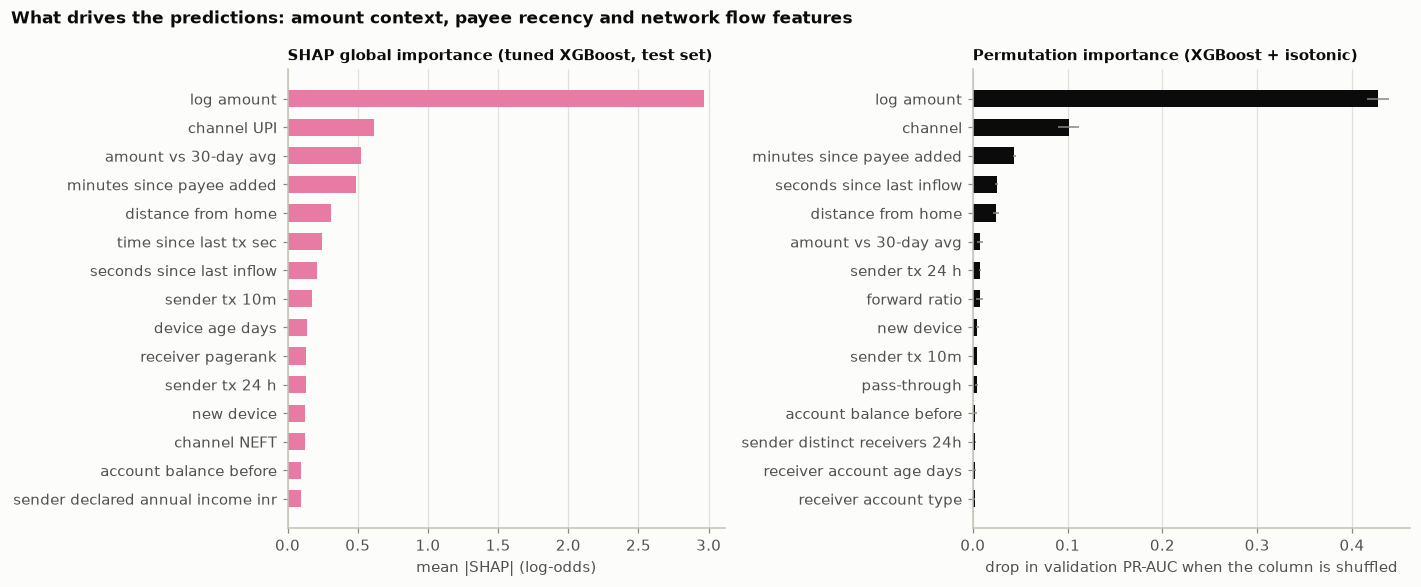

In [8]:
xgb = joblib.load(FIN / "xgboost_explainer.joblib")
sv, Xt, ev, names = X_.shap_values(xgb, Xte)
perm = pd.read_csv(R / "final_permutation_importance.csv")
F.fig_importance(X_.global_importance(sv, names), perm, S["production_model"]);
print("native pred_contribs vs shap.TreeExplainer:", X_.parity(xgb, Xte.iloc[:500]))

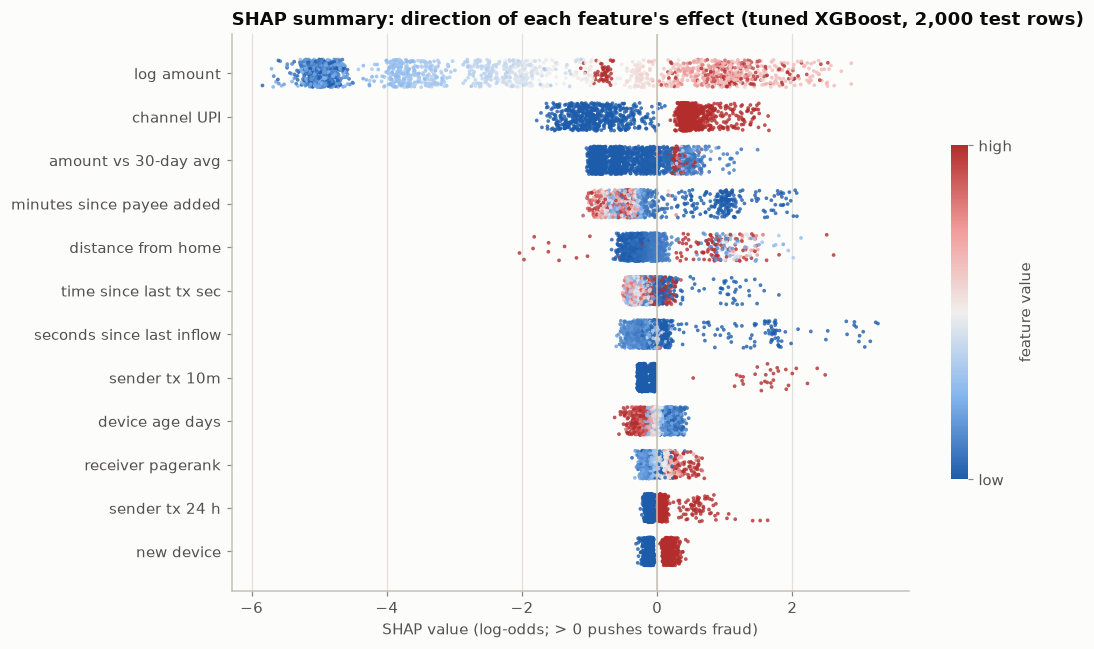

In [9]:
F.fig_beeswarm(sv, Xt, names);

- **Global:** the amount dominates (mean |SHAP| ≈ 3.0 log-odds), then channel (UPI), amount vs the 30-day average, minutes since the payee was added, distance from home, and the network timing features (seconds since last inflow, sender transactions in 10 minutes). Permutation importance on the production model gives the same top five, so the explanation is consistent across methods.
- **Direction (beeswarm):** large amounts, UPI, recently added payees, far-from-home locations, money received seconds before (pass-through) and sender bursts push towards fraud; old devices and long-standing payees push towards legitimate.
- **Serving (D-024):** XGBoost's native `pred_contribs=True` gives **exactly** the same values as `shap.TreeExplainer` (max difference 0.0), and the contributions sum to the model's log-odds. `ml-service` can explain every score without installing `shap` (saves memory on Render).
- The dominance of amount partly reflects the synthetic generator (Phase 0 audit); the report states this as a limitation.

fraud TXN_IND_202608_001768 S8 mule pass through P=1.00 risk=100 CRITICAL
    {'feature': 'sec_since_sender_last_inflow', 'value': 195.0, 'contribution': 1.4401, 'direction': 'towards fraud'}
    {'feature': 'is_pass_through', 'value': 1, 'contribution': 1.2027, 'direction': 'towards fraud'}
    {'feature': 'log_amount', 'value': 10.449462149623807, 'contribution': 1.1387, 'direction': 'towards fraud'}
    {'feature': 'distance_from_home_km', 'value': 23.98, 'contribution': 0.8458, 'direction': 'towards fraud'}
    {'feature': 'time_since_beneficiary_added_min', 'value': 27, 'contribution': 0.8448, 'direction': 'towards fraud'}
borderline TXN_IND_202608_006264 S5 new device suspicious P=0.95 risk=90 CRITICAL
    {'feature': 'distance_from_home_km', 'value': 128.09, 'contribution': 1.3082, 'direction': 'towards fraud'}
    {'feature': 'log_amount', 'value': 10.8232111852577, 'contribution': 1.2933, 'direction': 'towards fraud'}
    {'feature': 'time_since_beneficiary_added_min', 'value'

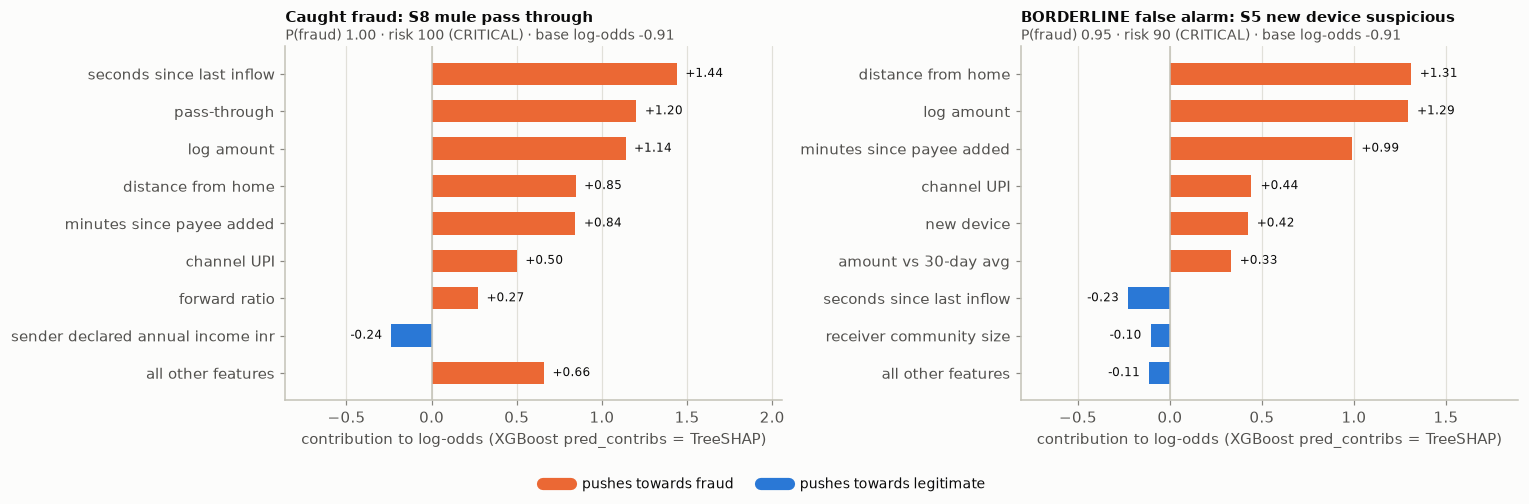

In [10]:
contrib = X_.contributions(xgb, Xte)
ex = S["explanations"]["examples"]
idx = {k: int(np.where(te["transaction_id"].astype(str).to_numpy() == v["transaction_id"])[0][0]) for k, v in ex.items()}
F.fig_local(contrib, idx, S);
for k, v in ex.items():
    print(k, v["transaction_id"], v["scenario"], f"P={v['p_fraud']:.2f} risk={v['risk_score']:.0f} {v['tier']}")
    for r in v["reasons"]:
        print("   ", r)

**Local explanations**, the payload `/score-transaction` will return:
- **Caught fraud (S8 mule pass-through):** money arrived 195 s earlier and was forwarded (pass-through), a large amount, and a payee added 27 minutes before. A textbook mule pattern; risk 100, CRITICAL.
- **BORDERLINE false alarm (S5 new device):** 128 km from home, a large amount, a payee added 45 minutes ago, and a new device. Every individual signal is suspicious, so the model is "right to be worried". This is why BORDERLINE cases belong in human review rather than automatic blocking.

## 7 · Hand-off to Phase 8 (services)
| Artifact (`artifacts/models/final/`) | Used by |
|---|---|
| `production_model.joblib` (0.43 MB) | `ml-service /score`: calibrated P(fraud) |
| `xgboost_explainer.joblib` | `ml-service /explain`: native TreeSHAP reasons (no `shap` import) |
| `risk_scorer.json` | gateway: weights, cut-offs, flag rates, overrides (numpy only) |
| `metrics.json` | `/models/compare`, dashboard ML Lab |
| `../anomaly/*` (Phase 6) | `ml-service /anomaly-score`: ONNX autoencoder → `anomaly_pct` |